# Phase 4B – Weather and the ideal line-up

The coach's two extra requests:

1. **Weather (4d).** The coach suspects that **temperature, wind, humidity and rain** change how the dogs perform. Support or refute each of the four.
2. **Line-up (4e).** Recommend the **ideal team line-up**.

Everything here calls `src/flyball/weather_effects.py` and `src/flyball/lineup.py`; `scripts/run_phase4b.py` rebuilds the same tables (`reports/phase4b/`) and figures. Choices and counts are logged in `ANALYSIS_LOG.md` Step 5.

**How to read the answers** (same rules as Phase 4A): every effect has a 95 % CI and a Holm-corrected p-value, plus an **equivalence test (TOST)** against the smallest change that matters to the coach: **0.05 s per dog run**, **0.2 s per heat**, **2 percentage points** for a rate. The verdict is one of *meaningful difference*, *real but negligible*, *no effect (equivalent)* or *inconclusive*.

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from flyball import competition, config, lineup, metrics, weather_effects as we
from flyball.plots import phase4 as plots, style

warnings.simplefilter("ignore")          # MixedLM convergence chatter
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.precision", 3)
style.apply()

t = metrics.load_processed()
heat_wx = pd.read_parquet(config.PROCESSED / "heat_weather.parquet")
weather_day = pd.read_csv(config.PROCESSED / "weather_day.csv")
runs_wx, heats_wx = we.run_frame(t["runs"], heat_wx), we.heat_frame(t["heats"], heat_wx)
print(f"{runs_wx['valid_speed'].sum():,} valid runs and {len(heats_wx):,} decided heats, all with weather")

32,801 valid runs and 8,464 decided heats, all with weather


---
## 4d – Weather

### 1. The problem: weather travels with venue and season

Each competition is one venue on one weekend, so "a hot day" is also "Máchale in July". And the weather variables move together: warm hours are dry hours. The table shows how strongly (correlation, and the variance inflation factor `vif`: above ~5 a variable is largely predictable from the others).

In [2]:
corr = we.correlations(heats_wx, weather_day)
display(corr)

,variable,temp_c,humidity_pct,wind_ms,precip_3h_mm,precip_24h_mm,gust_ms,months,vif,level,n
0,temp_c,1.000,-0.659,-0.307,-0.028,-0.438,-0.320,0.058,3.082,heat,4270
1,humidity_pct,-0.659,1.000,-0.051,0.430,0.308,-0.052,-0.070,2.891,heat,4270
2,wind_ms,-0.307,-0.051,1.000,-0.157,0.129,0.932,0.011,8.076,heat,4270
3,precip_3h_mm,-0.028,0.430,-0.157,1.000,0.290,-0.200,-0.115,1.718,heat,4270
4,precip_24h_mm,-0.438,0.308,0.129,0.290,1.000,0.177,0.110,1.512,heat,4270
5,gust_ms,-0.320,-0.052,0.932,-0.200,0.177,1.000,0.065,8.324,heat,4270
6,months,0.058,-0.070,0.011,-0.115,0.110,0.065,1.000,1.075,heat,4270
7,temp_c,1.000,-0.669,-0.328,-0.037,-0.526,-0.361,0.156,2.993,venue-day,22
8,humidity_pct,-0.669,1.000,0.155,0.407,0.379,0.205,0.057,2.933,venue-day,22
9,wind_ms,-0.328,0.155,1.000,0.118,0.324,0.924,-0.029,7.524,venue-day,22


- **Temperature and humidity** move against each other (r ≈ −0.66): you can't change one without the other. They are still separable (VIF ≈ 3), but their effects should be read together.
- **Gusts are almost the same as mean wind** (r 0.93), so only mean wind goes into the models; gusts are a sensitivity check.
- **Months into the season** is barely related to the weather *per heat*, but the cold days are April, May and October, so the season trend must be kept apart from temperature.

### 2. The main model: the same dog at the same competition

To separate weather from venue, each dog is compared **only with itself at the same competition**: Saturday vs Sunday, morning vs afternoon. Venue, ground and the dog's form that weekend cancel out. Model (per outcome):

`outcome ~ temperature (below / above 20 °C) + humidity + wind + rain in last 3 h + position + hurdle + run number that day + second day of the event`, dog × competition removed, errors clustered on the 22 venue-days (t distribution with 21 df, because that is few clusters).

Two controls were added for reasons the data showed:
- **run number that day** (fatigue): temperature rises with the clock, and so does the number of runs a dog has done;
- **second day of the event**: at 9 of the 11 two-day events Sunday was cooler than Saturday (clearly so at 6). Without this control, "warmer = more faults" appeared; with it, that signal vanished (see §4).

,sample,outcome,contrast,estimate,ci_low,ci_high,pct,p_holm,p_tost,verdict
0,field,run time,temperature +10 °C (below 20 °C),0.003,-0.007,1.334e-02,0.079,5.741e-01,1.490e-09,no effect (equivalent)
1,field,run time,temperature +10 °C (above 20 °C),0.083,0.050,1.174e-01,1.954,2.006e-04,9.756e-01,meaningful difference
2,field,run time,humidity +20 pp,0.018,0.007,2.982e-02,0.425,1.551e-02,5.765e-06,real but negligible
3,field,run time,wind +3 m/s,-0.007,-0.019,4.997e-03,-0.164,5.741e-01,1.299e-07,no effect (equivalent)
4,field,run time,rain in the last 3 h,-0.005,-0.014,2.951e-03,-0.128,5.741e-01,1.731e-10,no effect (equivalent)
30,field,clean heat time,temperature +10 °C (below 20 °C),-0.062,-0.148,2.277e-02,NaN,5.698e-01,1.490e-03,no effect (equivalent)
31,field,clean heat time,temperature +10 °C (above 20 °C),0.707,0.308,1.105e+00,NaN,6.824e-03,9.924e-01,meaningful difference
32,field,clean heat time,humidity +20 pp,0.038,-0.078,1.533e-01,NaN,1.000e+00,4.096e-03,no effect (equivalent)
33,field,clean heat time,wind +3 m/s,0.008,-0.093,1.082e-01,NaN,1.000e+00,3.399e-04,no effect (equivalent)
34,field,clean heat time,rain in the last 3 h,-0.014,-0.058,2.897e-02,NaN,1.000e+00,6.756e-09,no effect (equivalent)


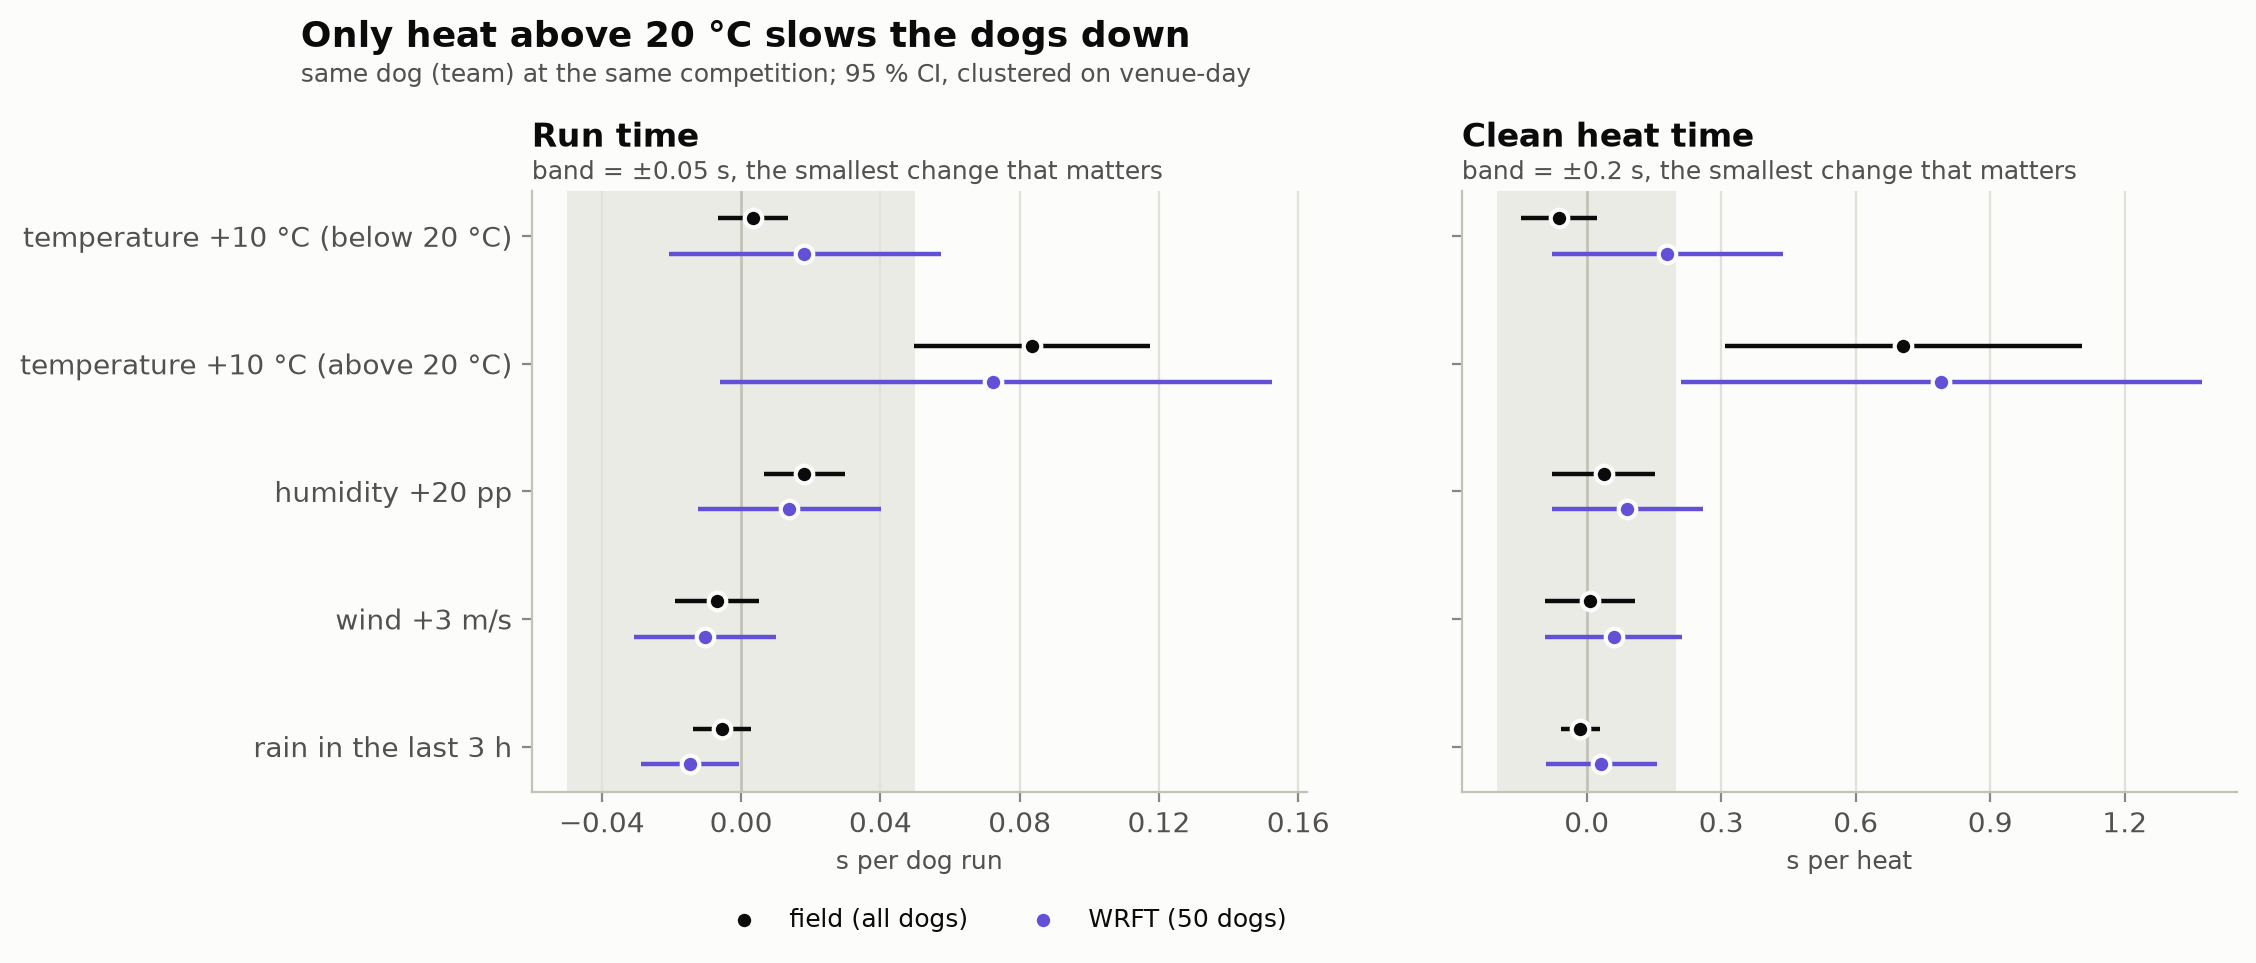

In [3]:
main = we.within_competition(runs_wx, heats_wx)
effects = main["effects"]
cols = ["sample", "outcome", "contrast", "estimate", "ci_low", "ci_high", "pct", "p_holm", "p_tost", "verdict"]
display(effects[effects["outcome"].isin(["run time", "clean heat time"])][cols])
display(Image(style.save(plots.weather_forest(effects), "weather_forest", "phase4")))

- **Heat above 20 °C slows the dogs: +0.083 s per run for every 10 °C** (95 % CI 0.050–0.117 s, +1.9 %), all dogs. That is about **+0.3 s per heat** from the four runs; the heat-level model gives +0.7 s per clean heat (CI 0.3–1.1 s). Both are *meaningful differences*.
- **Below 20 °C temperature doesn't matter** (+0.003 s per 10 °C, equivalent to zero).
- **Humidity:** +0.018 s per run for +20 pp, real but well inside the 0.05 s margin: *negligible*.
- **Wind and rain:** shown to be inside the margin: *no effect*.
- **WRFT's own 50 dogs** point the same way (+0.072 s per run above 20 °C), but alone they are too few for a firm verdict; the physiology is the same, so the all-dog result is the one to use.

### 3. Faults and the other outcomes

In [4]:
display(effects[~effects["outcome"].isin(["run time", "clean heat time"]) & effects["sample"].eq("field")][cols])
verdict = we.coach_verdict(effects)
display(verdict)

,sample,outcome,contrast,estimate,ci_low,ci_high,pct,p_holm,p_tost,verdict
5,field,start time,temperature +10 °C (below 20 °C),-1.307e-02,-0.020,-5.789e-03,NaN,0.006,3.063e-02,real but negligible
6,field,start time,temperature +10 °C (above 20 °C),-8.686e-06,-0.020,2.011e-02,NaN,1.000,2.566e-02,no effect (equivalent)
7,field,start time,humidity +20 pp,3.030e-03,-0.003,9.082e-03,NaN,1.000,4.338e-06,no effect (equivalent)
8,field,start time,wind +3 m/s,-3.355e-03,-0.012,5.069e-03,NaN,1.000,2.503e-04,no effect (equivalent)
9,field,start time,rain in the last 3 h,1.118e-03,-0.004,5.993e-03,NaN,1.000,3.692e-08,no effect (equivalent)
10,field,racing pass time,temperature +10 °C (below 20 °C),-1.865e-02,-0.036,-1.485e-03,NaN,0.173,4.356e-01,inconclusive
11,field,racing pass time,temperature +10 °C (above 20 °C),2.422e-03,-0.024,2.905e-02,NaN,1.000,9.214e-02,inconclusive
12,field,racing pass time,humidity +20 pp,1.097e-03,-0.010,1.248e-02,NaN,1.000,1.190e-03,no effect (equivalent)
13,field,racing pass time,wind +3 m/s,4.390e-03,-0.014,2.269e-02,NaN,1.000,4.525e-02,no effect (equivalent)
14,field,racing pass time,rain in the last 3 h,-3.941e-03,-0.011,3.460e-03,NaN,1.000,9.545e-05,no effect (equivalent)


,factor,speed,reliability,field_run_effect,field_meaningful,wrft_meaningful
0,temperature,supported,inconclusive,temperature +10 °C (below 20 °C): +0.003 s/run (-0.007 t...,"run time, temperature +10 °C (above 20 °C); clean heat t...",
1,humidity,refuted (too small to matter),inconclusive,humidity +20 pp: +0.018 s/run (+0.007 to +0.030),,"early-pass rate, humidity +20 pp"
2,wind,refuted (too small to matter),inconclusive,wind +3 m/s: -0.007 s/run (-0.019 to +0.005),,
3,rain,refuted (too small to matter),inconclusive,rain in the last 3 h: -0.005 s/run (-0.014 to +0.003),,


- No weather factor has a meaningful effect on **false starts, early passes, run faults or the clean-heat rate** once the second day is controlled for. Most are *inconclusive*: the CIs are wider than ±2 pp, so a small effect can't be ruled out either.
- One WRFT-only result: **early passes fall by 7.5 pp per +20 pp humidity**. It is a single hit among 40 WRFT tests, humid hours are the cool morning hours, and the all-dog sample shows nothing similar. It is reported as a lead, not as evidence.

### 4. A finding on the side: the second day is much cleaner

The control terms of the same models:

In [5]:
ctrl = main["controls"]
display(ctrl[ctrl["control"].isin(["second day of the event", "each earlier run that day (dog)"])])

,sample,outcome,control,unit,estimate,ci_low,ci_high,p_value
1,field,run time,each earlier run that day (dog),s per run,5.388e-03,4.264e-03,6.512e-03,2.051e-09
2,field,run time,second day of the event,s per run,1.735e-04,-8.830e-03,9.177e-03,9.684e-01
4,field,start time,each earlier run that day (dog),s,2.957e-04,-3.823e-04,9.736e-04,3.747e-01
5,field,start time,second day of the event,s,3.412e-03,-2.448e-03,9.271e-03,2.394e-01
7,field,racing pass time,each earlier run that day (dog),s,-2.046e-03,-3.107e-03,-9.849e-04,6.349e-04
8,field,racing pass time,second day of the event,s,2.240e-02,7.456e-03,3.735e-02,5.215e-03
10,field,false-start rate,each earlier run that day (dog),share,-3.080e-03,-5.099e-03,-1.062e-03,4.576e-03
11,field,false-start rate,second day of the event,share,-5.622e-02,-7.063e-02,-4.181e-02,6.557e-08
13,field,early-pass rate,each earlier run that day (dog),share,-7.196e-04,-2.498e-03,1.058e-03,4.094e-01
14,field,early-pass rate,second day of the event,share,-6.602e-02,-8.341e-02,-4.863e-02,1.016e-07


- **Same team, same event, second day: +19 pp clean heats** (all teams; WRFT +16 pp), with **5.6 pp fewer false starts** and **6.6 pp fewer early passes** (WRFT: 10 pp fewer false starts). Run times don't change.
- The data can't say *why* (nerves, warming up to a new ground, Sunday's different race format). But it is large, consistent and directly actionable: **Saturday is where WRFT gives heats away**. It goes to Phase 5 as a finding in its own right.
- **Fatigue:** each earlier run that day adds about 0.005 s to the next run. Small, but it adds up over a 20-run day.

### 5. Robustness

In [6]:
sens = we.sensitivity(runs_wx, heats_wx)
key = sens[sens["contrast"].eq("temperature +10 °C (above 20 °C)")]
display(key.pivot_table(index="model", columns="outcome", values="estimate", sort=False).round(3))

outcome,run time,false-start rate,early-pass rate,clean heat time,clean-heat rate
model,,,,,
baseline,0.083,-0.050,-0.057,0.707,0.081
no fatigue control,0.097,-0.058,-0.059,0.725,0.093
no second-day control,0.083,0.006,0.006,0.866,-0.099
plus hour of day,0.084,-0.049,-0.057,0.701,0.081
hinge at 15 °C,0.040,-0.046,-0.055,0.278,0.096
hinge at 25 °C,0.088,-0.022,-0.049,0.928,0.090
apparent temperature,0.054,-0.063,-0.067,0.508,0.087
wet ground: >= 1 mm in last 24 h,0.083,-0.053,-0.063,0.731,0.090
gusts (/2) instead of mean wind,0.085,-0.054,-0.052,0.688,0.077


- The **run-time heat effect** is stable: **0.062–0.097 s per run** in every variant that keeps the 20 °C hinge, including leaving any single competition out. Moving the hinge to 15 °C spreads the same rise over a wider range (0.040 s per 10 °C above 15 °C). Apparent temperature gives 0.054 s (it mixes in humidity).
- The **clean-heat-time** effect leans on one event: without Máchale (the 33 °C heatwave) it drops from 0.71 to 0.28 s per heat. So the heat-level number is less certain than the per-run one.
- Without the second-day control, temperature *below* 20 °C appears to raise fault rates. That disappears with the control: it was a Saturday/Sunday effect.

**Stricter checks.** Comparing a dog only with itself *on the same day* leaves just the morning-to-afternoon swing (a few °C). It is too small to test heat: every temperature estimate is *inconclusive*. The WRFT mixed model (random dog and ring-day effects) behaves the same way, because its ring-day effect also absorbs most of the day-to-day weather. Wind and rain stay equivalent to zero in both.

In [7]:
display(we.within_day(runs_wx, heats_wx)[cols].query("sample == 'field'"))
display(we.wrft_mixed(runs_wx))

,sample,outcome,contrast,estimate,ci_low,ci_high,pct,p_holm,p_tost,verdict
0,field,run time,temperature +10 °C (below 20 °C),-0.025,-0.073,2.433e-02,-0.582,0.608,1.499e-01,inconclusive
1,field,run time,temperature +10 °C (above 20 °C),0.049,-0.009,1.072e-01,1.141,0.281,4.820e-01,inconclusive
2,field,run time,humidity +20 pp,0.018,-0.001,3.663e-02,0.414,0.259,9.050e-04,no effect (equivalent)
3,field,run time,wind +3 m/s,-0.003,-0.018,1.236e-02,-0.070,0.688,1.301e-06,no effect (equivalent)
4,field,run time,rain in the last 3 h,-0.010,-0.020,-5.439e-04,-0.239,0.197,1.436e-08,no effect (equivalent)
5,field,clean heat time,temperature +10 °C (below 20 °C),-0.200,-0.688,2.891e-01,NaN,1.000,4.992e-01,inconclusive
6,field,clean heat time,temperature +10 °C (above 20 °C),0.006,-0.286,2.981e-01,NaN,1.000,9.081e-02,inconclusive
7,field,clean heat time,humidity +20 pp,-0.037,-0.243,1.702e-01,NaN,1.000,5.766e-02,inconclusive
8,field,clean heat time,wind +3 m/s,0.049,-0.174,2.724e-01,NaN,1.000,8.734e-02,inconclusive
9,field,clean heat time,rain in the last 3 h,-0.035,-0.084,1.430e-02,NaN,0.777,3.240e-07,no effect (equivalent)


,sample,model,outcome,factor,contrast,estimate,ci_low,ci_high,pct,p_value
0,WRFT,mixed (dog + ring-day random),run time,temperature,temperature +10 °C (below 20 °C),-0.076,-0.143,-7.627e-03,-1.778,0.030
1,WRFT,mixed (dog + ring-day random),run time,temperature,temperature +10 °C (above 20 °C),0.010,-0.068,8.976e-02,0.237,0.801
2,WRFT,mixed (dog + ring-day random),run time,humidity,humidity +20 pp,0.037,0.009,6.531e-02,0.860,0.011
3,WRFT,mixed (dog + ring-day random),run time,wind,wind +3 m/s,0.029,0.003,5.586e-02,0.688,0.028
4,WRFT,mixed (dog + ring-day random),run time,rain,rain in the last 3 h,-0.015,-0.030,-2.787e-05,-0.348,0.050


### 6. How much of a good or bad day is weather?

The Phase 4A speed index says how fast the same dogs ran on each ring-day. Regressing it on the day's weather and the season:

,model,ring_days,venue_days,r2,adj_r2,loeo_r2
0,season only,28,22,0.201,0.171,-0.556
1,weather only,28,22,0.613,0.546,0.122
2,weather + season,28,22,0.768,0.715,0.569


,model,term,pct,ci_low,ci_high,p_value
7,weather + season,const,1.453,0.532,2.374,3.568e-03
8,weather + season,temp10,0.775,0.290,1.259,3.229e-03
9,weather + season,hum20,-0.016,-0.604,0.571,9.547e-01
10,weather + season,wind3,-0.311,-0.939,0.318,3.159e-01
11,weather + season,wet,-0.838,-1.165,-0.510,2.842e-05
12,weather + season,months,-0.184,-0.289,-0.080,1.429e-03


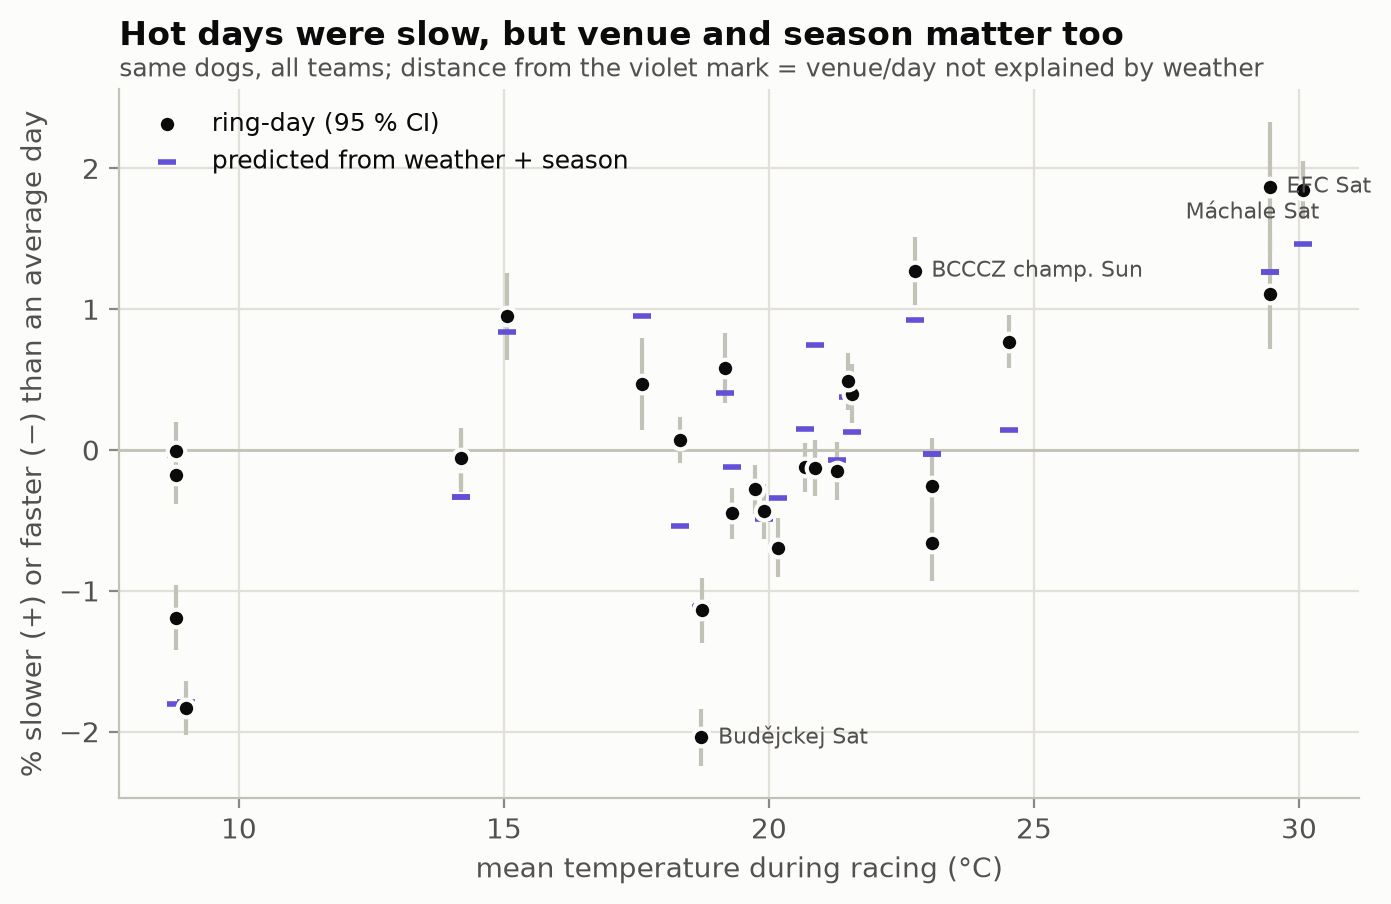

In [8]:
index_field = competition.speed_index(t["runs"][t["runs"]["dog_key"].notna()], "field")
meta = we.day_meta(index_field, weather_day)
display(meta["fit"])
display(meta["coefficients"].query("model == 'weather + season'"))
display(Image(style.save(plots.weather_vs_venue(meta["days"]), "weather_vs_venue", "phase4")))

- **Weather plus season explains 77 % of the day-to-day differences** in speed (R²; 57 % when each event is predicted from the other events only). Season alone explains 20 %.
- Warmer days are slower (+0.78 % per 10 °C of daily mean) and dogs get faster through the season (−0.18 % per month).
- Rainy days come out *faster* (−0.8 %) at the day level, but the within-competition model shows no rain effect at all. Rainy days are also cloudy and cool, so this is probably the sun, not the rain.
- The remaining quarter is the venue and the day itself: Budějckej Saturday and EFC Sunday were faster than their weather predicts.

### 7. The shape of the heat effect, and a machine-learning check

,features,runs,folds,run_r2,ring_days,day_r2,day_corr,sd_run_pct,sd_day_pct
0,weather + fatigue,32777,11,0.011,28,-0.057,0.385,3.367,0.547
1,fatigue only,32777,11,0.010,28,-0.208,-0.438,3.367,0.547


,feature,mse_increase
0,run_no_today,3.620e-01
1,temp_c,3.438e-02
2,humidity_pct,3.017e-02
3,precip_3h_mm,6.576e-03
4,wind_ms,5.320e-04


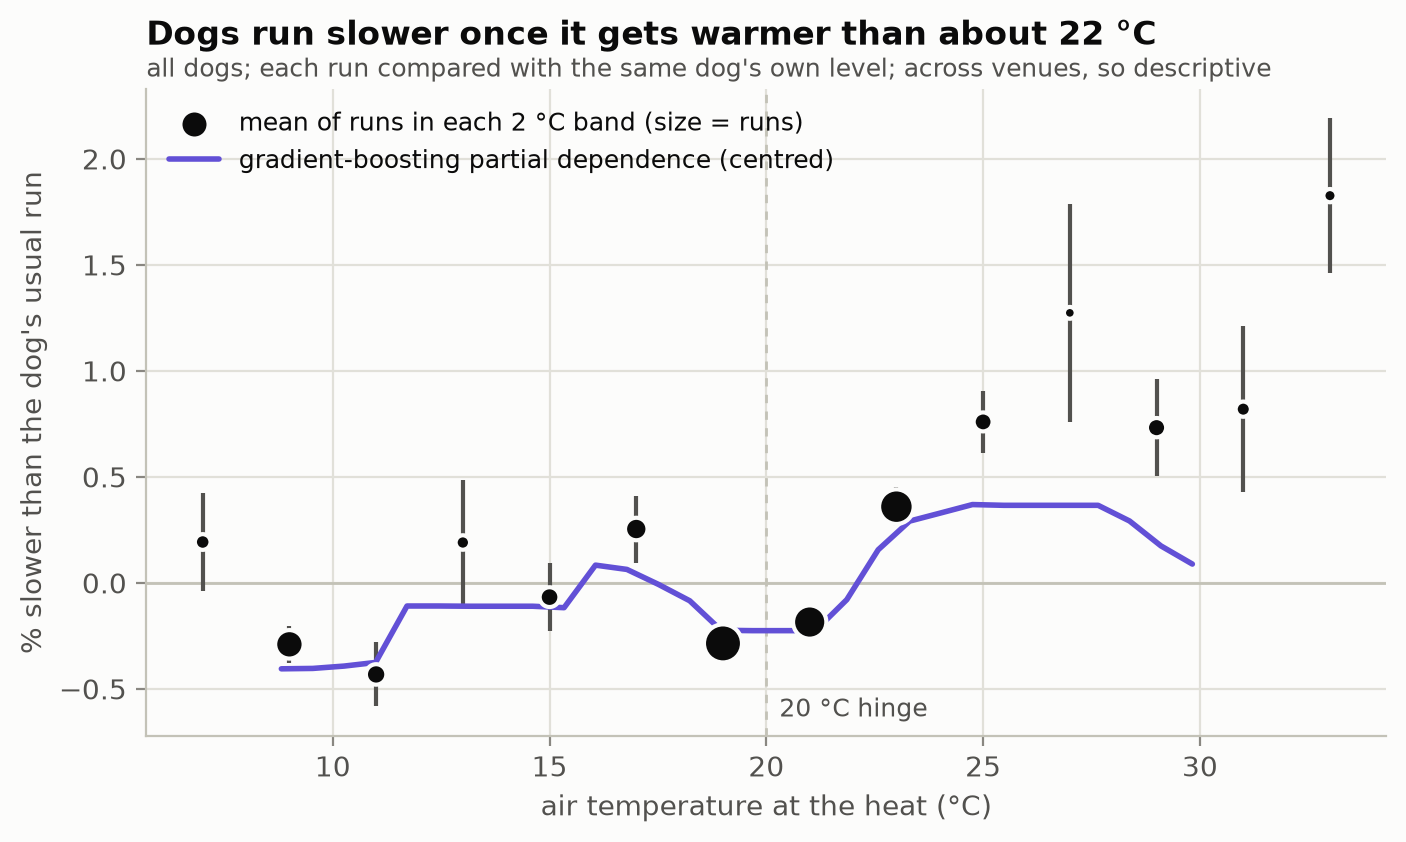

In [9]:
gbm = we.gbm_check(runs_wx)
display(gbm["scores"], gbm["importance"])
display(Image(style.save(plots.heat_curve(we.temperature_curve(runs_wx), gbm["pdp"]), "heat_curve", "phase4")))

- **Binned means (dots):** flat up to about 22 °C, then rising: +0.8 % at 25 °C, +1.8 % at 33 °C.
- **Gradient boosting** (`HistGradientBoostingRegressor`), trained on the weather plus the dog's run number, always scored on a competition it never saw (11-fold leave-one-competition-out):
  - for single runs it explains almost nothing (R² ≈ 0.01): one run is mostly the dog's own noise;
  - at day level, the weather version tracks which days were slow (correlation 0.38), and the no-weather version doesn't (−0.44). Neither predicts an unseen event's level well, because the venue is unknown to it;
  - its partial dependence on temperature (violet line) shows the same **step up between 21 and 24 °C**;
  - permutation importance ranks temperature and humidity well above rain and wind.
- Months and hour of day were tried as features and dropped: they extrapolate badly to an unseen event.

### Verdict on the coach's four factors

| Factor | Speed | Faults | In plain words |
|---|---|---|---|
| **Temperature** | **supported, above ~20 °C** | inconclusive | +0.08 s per dog run per 10 °C above 20 °C; nothing below 20 °C |
| Humidity | refuted (too small) | inconclusive | +0.02 s per run per +20 pp |
| Wind | refuted | inconclusive | within ±0.02 s per run |
| Rain | refuted | inconclusive | within ±0.015 s per run |

**For the coach:** heat is the only weather factor that costs speed. On a 30 °C day expect about 0.3 s per heat slower. Cooling, shade and rest between heats are worth planning for hot events. Wind and rain can be ignored. The bigger, controllable lever is the **first day of each event**.

---
## 4e – The ideal line-up

### 1. A profile for every dog

A heat time = start + 4 runs + 3 passes, and every fault costs a rerun (≈ 8 s, Phase 3). Each WRFT dog gets:
- **speed:** a mixed model with a random intercept *and* a random hurdle slope per dog. A dog seen at one height borrows the team's slope; a negative slope (faster over higher hurdles) is set to 0;
- **start and pass time:** shrunken means (a dog with 5 attempts can't top the list on luck), held passes > 1 s left out;
- **false-start, early-pass and run-fault probabilities:** empirical-Bayes rates;
- **height:** the hurdle the dog actually set as the smallest dog in 2023, or its master height;
- **pool:** every dog with ≥ 20 valid runs (42 dogs, the decision for this phase). Only dogs with ≥ 10 starts may run first.

In [10]:
cost = lineup.fault_cost(t["heats"])
prof = lineup.dog_profiles(t["runs"], t["dogs"], t["hurdle_check"])
print(f"fault cost {cost:.2f} s; {prof['in_pool'].sum()} dogs in the pool; "
      f"{prof.attrs['n_slopes_floored']} hurdle slopes floored at 0")
display(prof[prof["in_pool"]].sort_values("run_25cm_s").head(15)[
    ["dog", "height_cm", "run_25cm_s", "starts", "start_s", "false_start_p", "pass_s", "early_pass_p", "run_fault_p"]])

fault cost 7.96 s; 42 dogs in the pool; 9 hurdle slopes floored at 0


,dog,height_cm,run_25cm_s,starts,start_s,false_start_p,pass_s,early_pass_p,run_fault_p
34,Moon,27.5,3.931,0,0.184,0.158,0.170,0.131,0.003
3,Alfie,27.5,3.963,0,0.184,0.158,0.151,0.081,0.010
19,Enola,32.5,3.976,156,0.134,0.101,0.250,0.064,0.002
31,Maggie,27.5,3.992,14,0.099,0.074,0.151,0.108,0.006
49,Tyna,27.5,4.039,0,0.184,0.158,0.146,0.083,0.008
37,Pax,25.0,4.064,26,0.113,0.104,0.152,0.097,0.003
46,Sunny,32.5,4.093,118,0.108,0.170,0.266,0.091,0.003
44,Sirius,32.5,4.125,2,0.466,0.143,0.285,0.069,0.037
14,Cookies,27.5,4.127,51,0.139,0.338,0.239,0.084,0.029
20,Falco,27.5,4.149,52,0.126,0.236,0.211,0.091,0.072


### 2. Every line-up, every order

Expected heat time = start + Σ runs at the smallest dog's hurdle + Σ passes + 8 s × expected number of faults. All 111,930 sets of 4 dogs × 24 orders (2.7 million line-ups) are scored, so the search is exhaustive.

In [11]:
top = lineup.search(prof, cost)
display(top.head(10)[["rank", "line_up", "expected_s", "no_fault_s", "runs_s", "fault_s", "p_clean", "hurdle_cm"]])
display(lineup.dog_frequency(top).head(8))
display(lineup.reserves(prof, top.iloc[0], cost))
speed_only = lineup.search(prof, 0.0, top=5)
display(speed_only[["rank", "line_up", "no_fault_s", "p_clean"]])

,rank,line_up,expected_s,no_fault_s,runs_s,fault_s,p_clean,hurdle_cm
0,1,Maggie > Enola > Pax > Alfie,19.281,16.602,15.950,2.680,0.705,25.0
1,2,Maggie > Alfie > Tyna > Enola,19.353,16.740,16.094,2.613,0.712,27.5
2,3,Maggie > Tyna > Pax > Enola,19.353,16.673,16.026,2.680,0.705,25.0
3,4,Maggie > Alfie > Alex > Enola,19.410,16.977,16.304,2.433,0.729,27.5
4,5,Maggie > Pax > Alex > Enola,19.427,16.928,16.255,2.500,0.722,25.0
5,6,Maggie > Tyna > Pax > Alfie,19.437,16.560,16.013,2.877,0.686,25.0
6,7,Maggie > Tyna > Alex > Enola,19.462,17.028,16.361,2.433,0.729,27.5
7,8,Pax > Enola > Tyna > Alfie,19.489,16.658,15.997,2.832,0.690,25.0
8,9,Maggie > Pax > Alex > Alfie,19.511,16.815,16.241,2.697,0.703,25.0
9,10,Alex > Enola > Pax > Alfie,19.543,16.876,16.224,2.667,0.706,25.0


,dog,appearances,best_rank,usual_position
0,Enola,40,1,dog4
1,Maggie,37,1,dog1
2,Alfie,29,1,dog4
3,Pax,26,1,dog2
4,Tyna,19,2,dog2
5,Alex,14,4,dog3
6,Nina,8,12,dog3
7,Sunny,6,11,dog3


,reserve,replaces,line_up,expected_s,cost_vs_a_team_s
0,Tyna,Pax,Maggie > Alfie > Tyna > Enola,19.353,0.072
1,Alex,Pax,Maggie > Alfie > Alex > Enola,19.410,0.128


,rank,line_up,no_fault_s,p_clean
0,1,Maggie > Alfie > Pax > Moon,16.476,0.653
1,2,Enola > Alfie > Pax > Moon,16.496,0.636
2,3,Enola > Maggie > Pax > Moon,16.525,0.620
3,4,Pax > Alfie > Tyna > Moon,16.532,0.640
4,5,Enola > Maggie > Pax > Alfie,16.538,0.652


- **A-team: Maggie > Enola > Pax > Alfie**, at 25 cm: **16.6 s without faults** (15.95 s for the 4 runs, the FCI clean time; real WRFT heats with the Enola, Maggie and Alfie core ran 15.7–16.3 s), **19.3 s expected** with fault risk, and a 70 % chance of a clean heat.
- **Reserves:** Tyna (costs 0.07 s if she replaces Pax) and Alex (0.13 s).
- **Enola** is in 40 of the top 50 line-ups. The model puts **Maggie first** because she starts fast (0.10 s) and rarely breaks (7 %), but that rests on only **14 starts**. Enola first is the proven order (156 starts, 10 % false starts): 0.06 s faster when clean, 0.5 s slower in expected time. **Advice:** trial Maggie as the starter in training; until then, Enola first is the safe choice.
- **Speed alone would pick Moon:** she is the fastest runner, but her 13 % early-pass rate costs more than her speed gains, so she drops out once faults count.
- **The order matters as much as the names.** The search puts the safest starter first and reliable passers behind.

### 3. The current teams

,team,current_order,current_expected_s,current_p_clean,best_order,gain_from_order_s,best_bench_swap,gain_from_swap_s,bench_options
0,wildrunners dreamers,Maggie > Sirius > Alfie > Tyna,19.833,0.683,Maggie > Tyna > Sirius > Alfie,3.472e-04,Sirius -> Pax,0.396,"Pax (+0.40 s), Sunny (+0.09 s), Ashley (+0.07 s)"
1,wildrunners hopefuls,Cookies > Enola > Maggie > Tyna,21.985,0.484,Maggie > Tyna > Cookies > Enola,2.249e+00,Cookies -> Pax,2.632,"Pax (+2.63 s), Sunny (+2.36 s), Ashley (+2.33 s)"
2,wildrunners maximini,Nina > Brooke > Bree > Alex,20.692,0.664,Bree > Brooke > Alex > Nina,3.550e-01,Brooke -> Pax,0.581,"Pax (+0.58 s), Sunny (+0.36 s), Ashley (+0.33 s)"
3,wildrunners nightfall,Nina > Falco > Gerry > Hector,21.651,0.597,Nina > Hector > Gerry > Falco,7.620e-05,Falco -> Pax,0.651,"Pax (+0.65 s), Sunny (+0.55 s), Moon (+0.49 s)"
4,wildrunners wonders,Rex > Hank > Hector > Gordon,26.008,0.558,Hank > Rex > Gordon > Hector,1.125e-01,Gordon -> Pax,3.717,"Pax (+3.72 s), Brix (+3.33 s), Easy (+3.05 s)"
5,wildrunners xxl,Rex > Hank > Gerry > Bailey,24.444,0.549,Gerry > Bailey > Rex > Hank,1.031e+00,Rex -> Pax,2.453,"Pax (+2.45 s), Sunny (+2.33 s), Moon (+2.27 s)"
6,wildrunners zephyr,Rex > Rocky > Scotty > Gordon,27.256,0.569,Rocky > Rex > Gordon > Scotty,1.345e+00,Gordon -> Pax,4.043,"Pax (+4.04 s), Sunny (+3.83 s), Ashley (+3.80 s)"


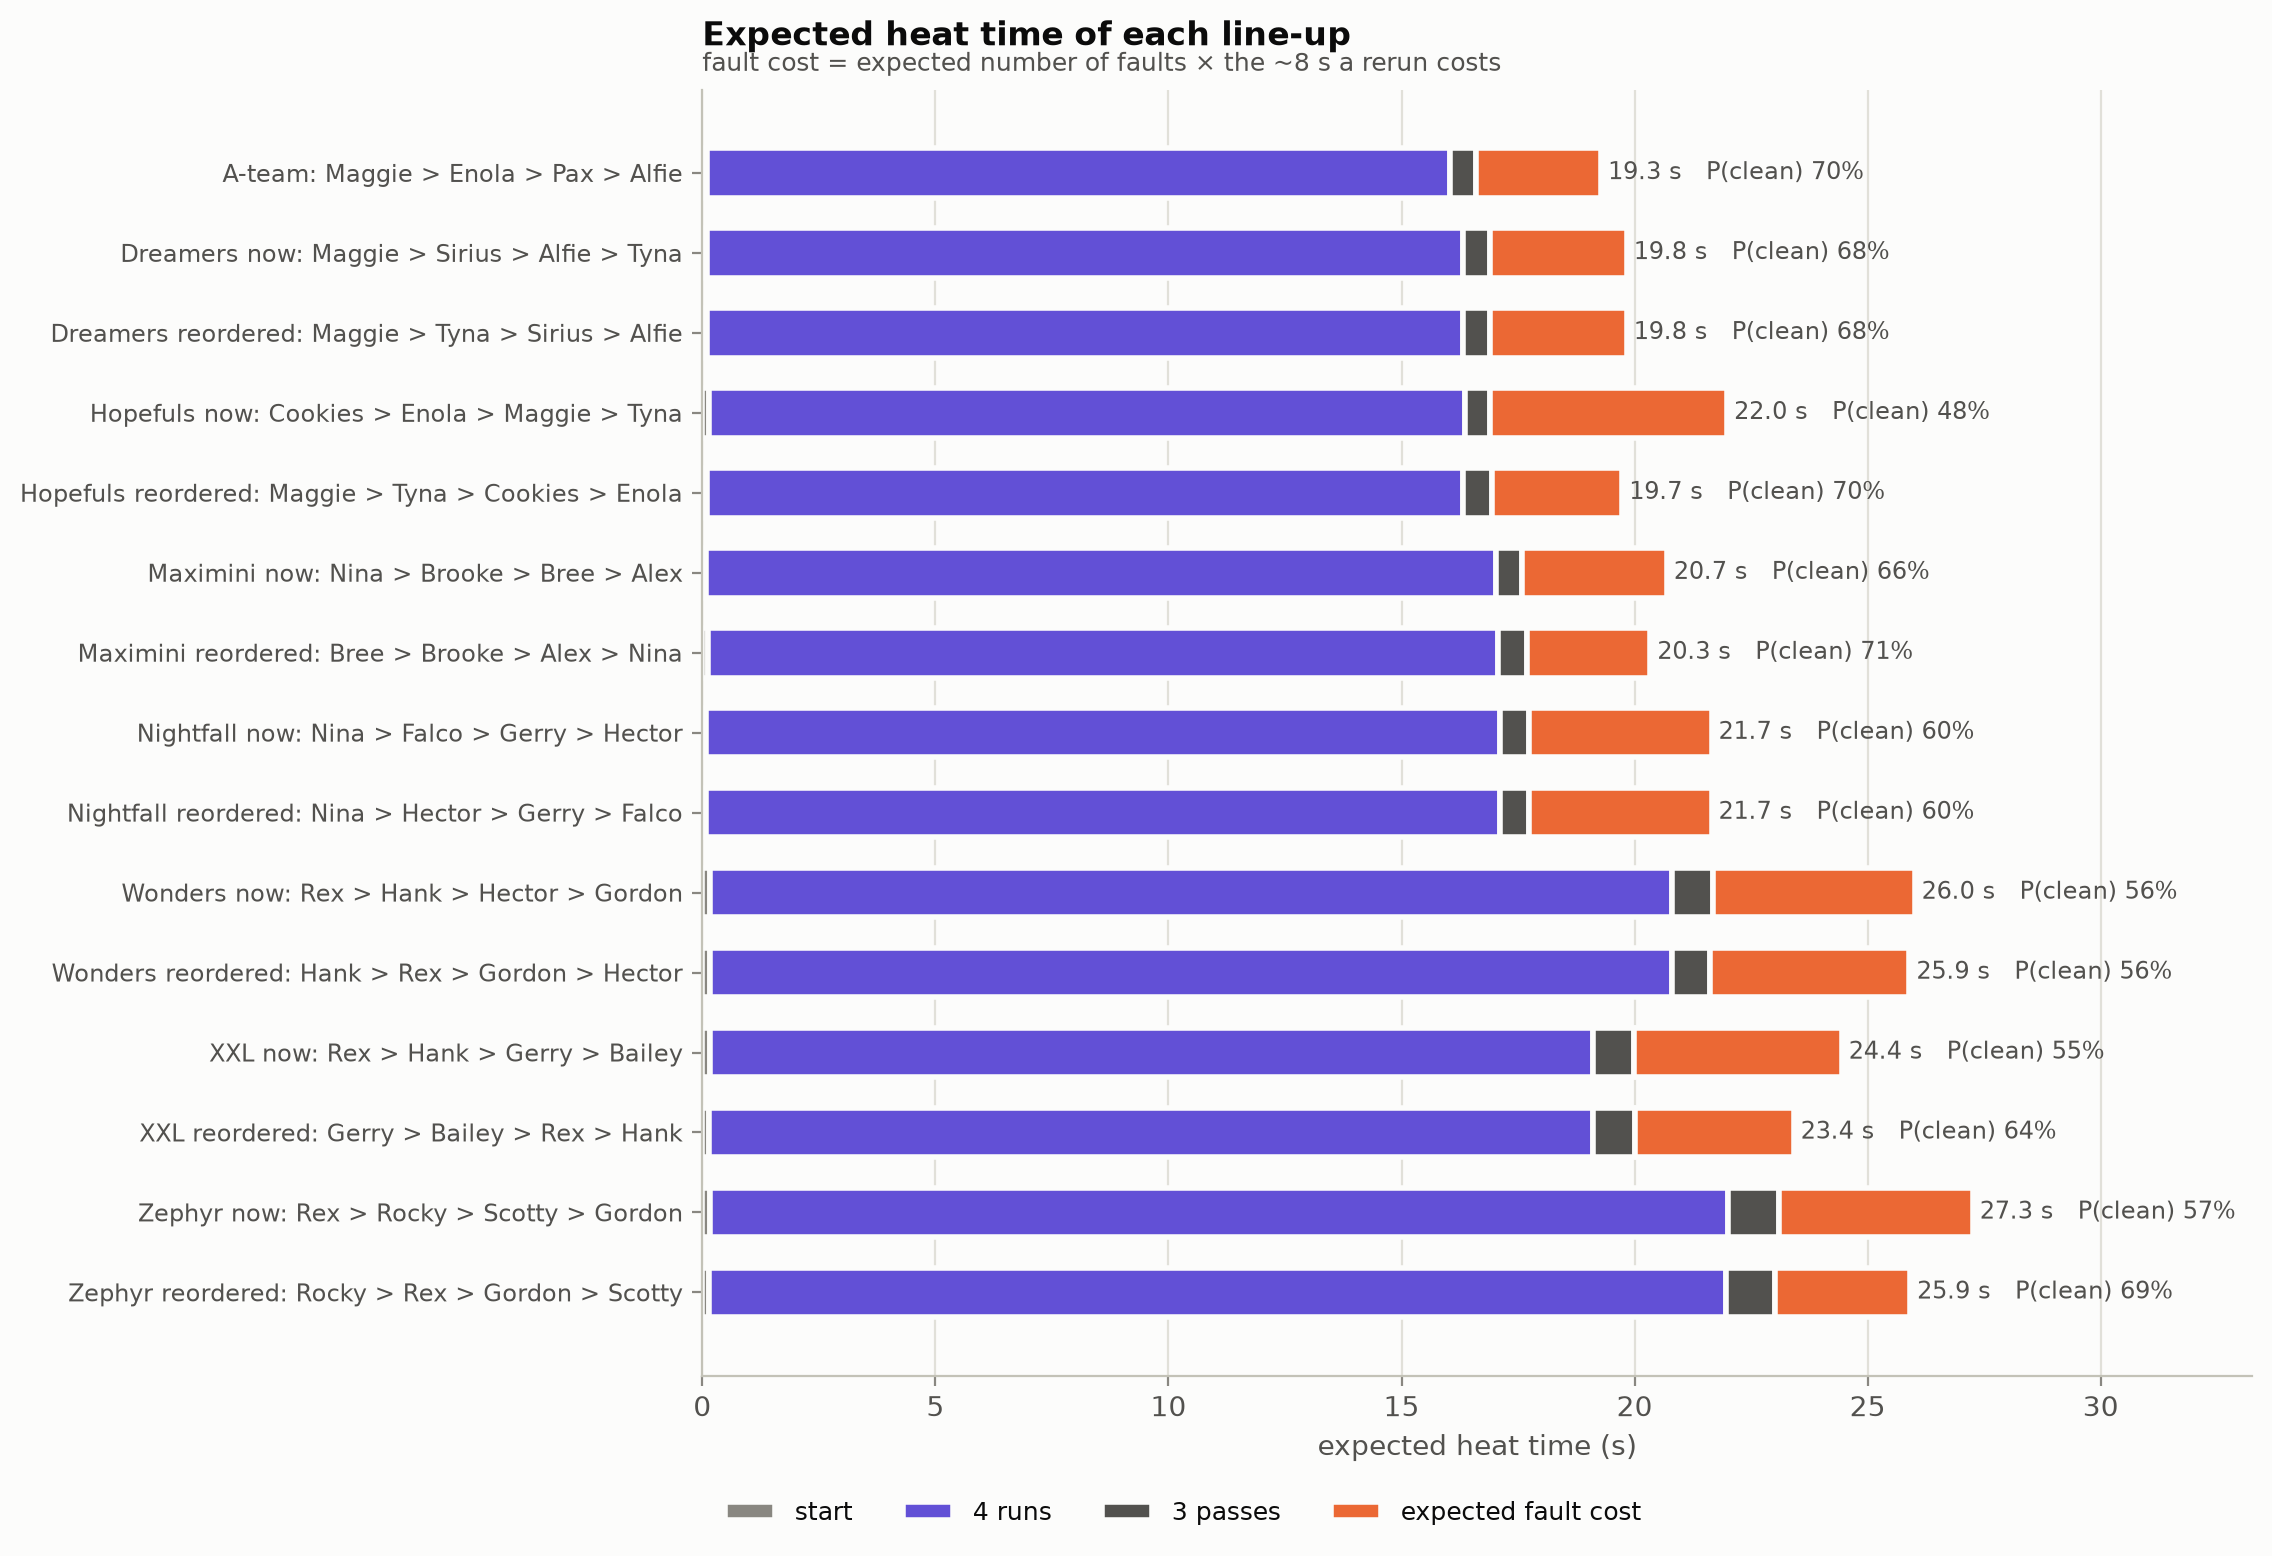

In [12]:
current = lineup.current_line_ups(t["runs"])
teams = lineup.team_recommendations(prof, current, cost)
display(teams[["team", "current_order", "current_expected_s", "current_p_clean", "best_order",
               "gain_from_order_s", "best_bench_swap", "gain_from_swap_s", "bench_options"]])
display(Image(style.save(plots.lineup_breakdown(lineup.comparison(prof, top.iloc[0], teams, cost)),
                         "lineup_breakdown", "phase4")))

- **Hopefuls: start with Maggie, not Cookies: about 2.2 s per heat** in expected time. Cookies false-starts 34 % of the time; Maggie 7 %.
- **XXL and Zephyr** gain 1.0–1.3 s from reordering alone; Maximini 0.4 s. Dreamers and Nightfall already run their best order.
- **Swaps** only use *bench* dogs (in no team's current line-up), so advice for one team never takes a dog from another. **Pax** is the best bench dog for every team, then Sunny and Ashley. Pax last raced in July, so check his availability first.
- Every bar is the same **4 runs** at about 16–22 s. The orange **fault cost** is where the line-ups differ most, which matches Phase 3: WRFT loses through faults, not speed.

### 4. Does a small "height dog" pay?

A dog under 25 cm lowers the hurdle for the whole team (≈ 0.02 s per dog per 2.5 cm step). But it has to run itself.

,height_dog,height_cm,run_at_own_height_s,best_line_up_with_it,hurdle_cm,expected_s,hurdle_saving_s,best_without_small_dog,without_expected_s,gain_vs_without_s
0,Easy,20.0,4.500,Maggie > Enola > Easy > Alfie,20.0,19.830,0.407,Maggie > Enola > Pax > Alfie,19.281,-0.548
1,Kesha,22.5,4.969,Maggie > Enola > Kesha > Alfie,22.5,20.377,0.273,Maggie > Enola > Pax > Alfie,19.281,-1.096
2,Dusty,22.5,6.342,Maggie > Enola > Dusty > Alfie,22.5,21.693,0.273,Maggie > Enola > Pax > Alfie,19.281,-2.411
3,Gordon,15.0,6.937,Maggie > Enola > Gordon > Alfie,15.0,21.707,0.669,Maggie > Enola > Pax > Alfie,19.281,-2.425


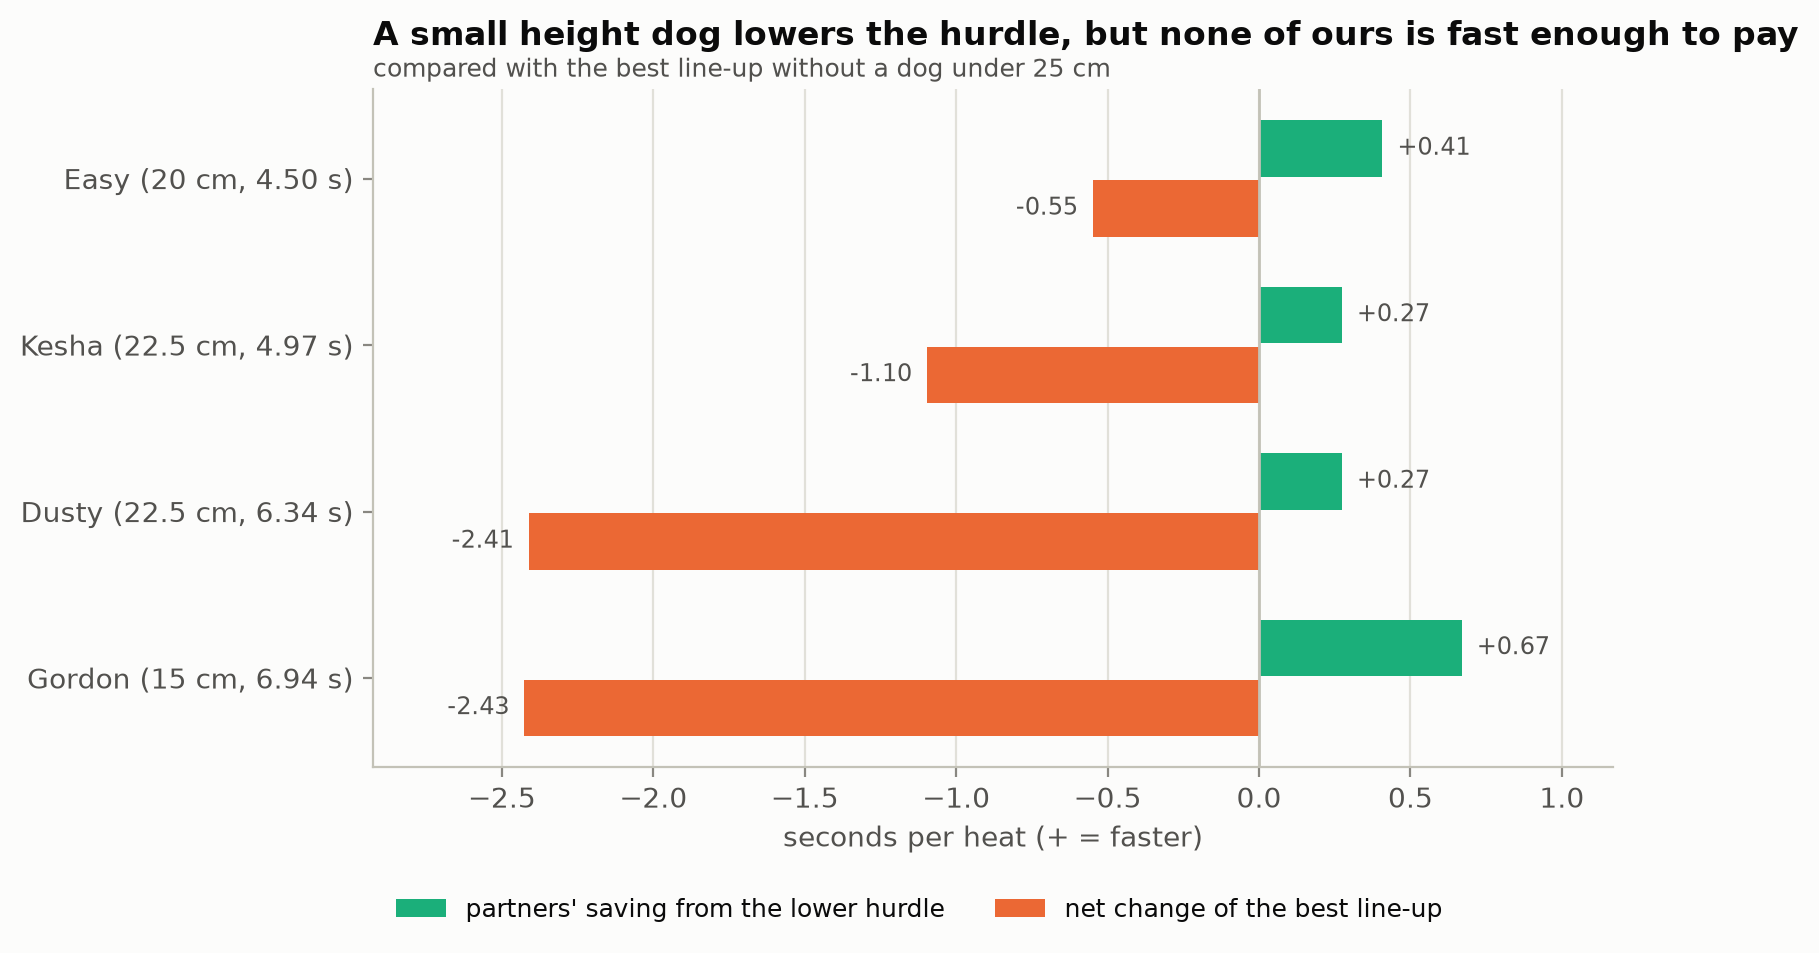

In [13]:
height = lineup.height_dog(prof, cost)
display(height)
display(Image(style.save(plots.height_dog_tradeoff(height), "height_dog_tradeoff", "phase4")))

- **None of WRFT's small dogs pays off for a top team.** Easy (20 cm) comes closest: the lower hurdle saves the partners 0.4 s, but the best line-up with her is still 0.55 s slower than without.
- Gordon (15 cm) saves the most hurdle time (0.67 s) but is 2.4 s slower overall: his 6.9 s run is 3 s slower than a top dog's.
- A small dog would pay off only if it ran within about 0.1–0.2 s of the big dogs. **Keep small dogs for teams where the lower division is the goal.**

### 5. Does the model predict real heats? (back-test)

The profiles were fitted on **April–July only** and used to predict the September–October WRFT heats.

,check,n,mae_s,bias_s,spearman,brier,auc,mean_predicted,observed
0,clean time: model,137,0.337,0.083,0.913,NaN,NaN,NaN,NaN
1,clean time: baseline (sum of raw medians),137,0.312,0.086,0.893,NaN,NaN,NaN,NaN
2,clean heat: model P(clean),214,NaN,NaN,NaN,0.234,0.552,0.563,0.64
3,clean heat: baseline (training rate),214,NaN,NaN,NaN,0.243,NaN,0.528,0.64


{'test_heats': 261, 'unprofiled': 47, 'unprofiled_dogs': ['Easy', 'Kent', 'Milo']}


,hurdle_cm,heats,model_bias_s,baseline_bias_s,model_mae_s,baseline_mae_s
0,15.0,11,-0.320,0.543,0.496,0.637
1,22.5,4,0.103,0.115,0.154,0.147
2,25.0,38,0.060,0.107,0.250,0.254
3,27.5,83,0.142,0.015,0.363,0.307
4,30.0,1,0.474,-0.005,0.474,0.005


,heats,predicted,observed
0,46,0.411,0.522
1,49,0.570,0.694
2,35,0.601,0.714
3,48,0.615,0.646
4,36,0.640,0.639


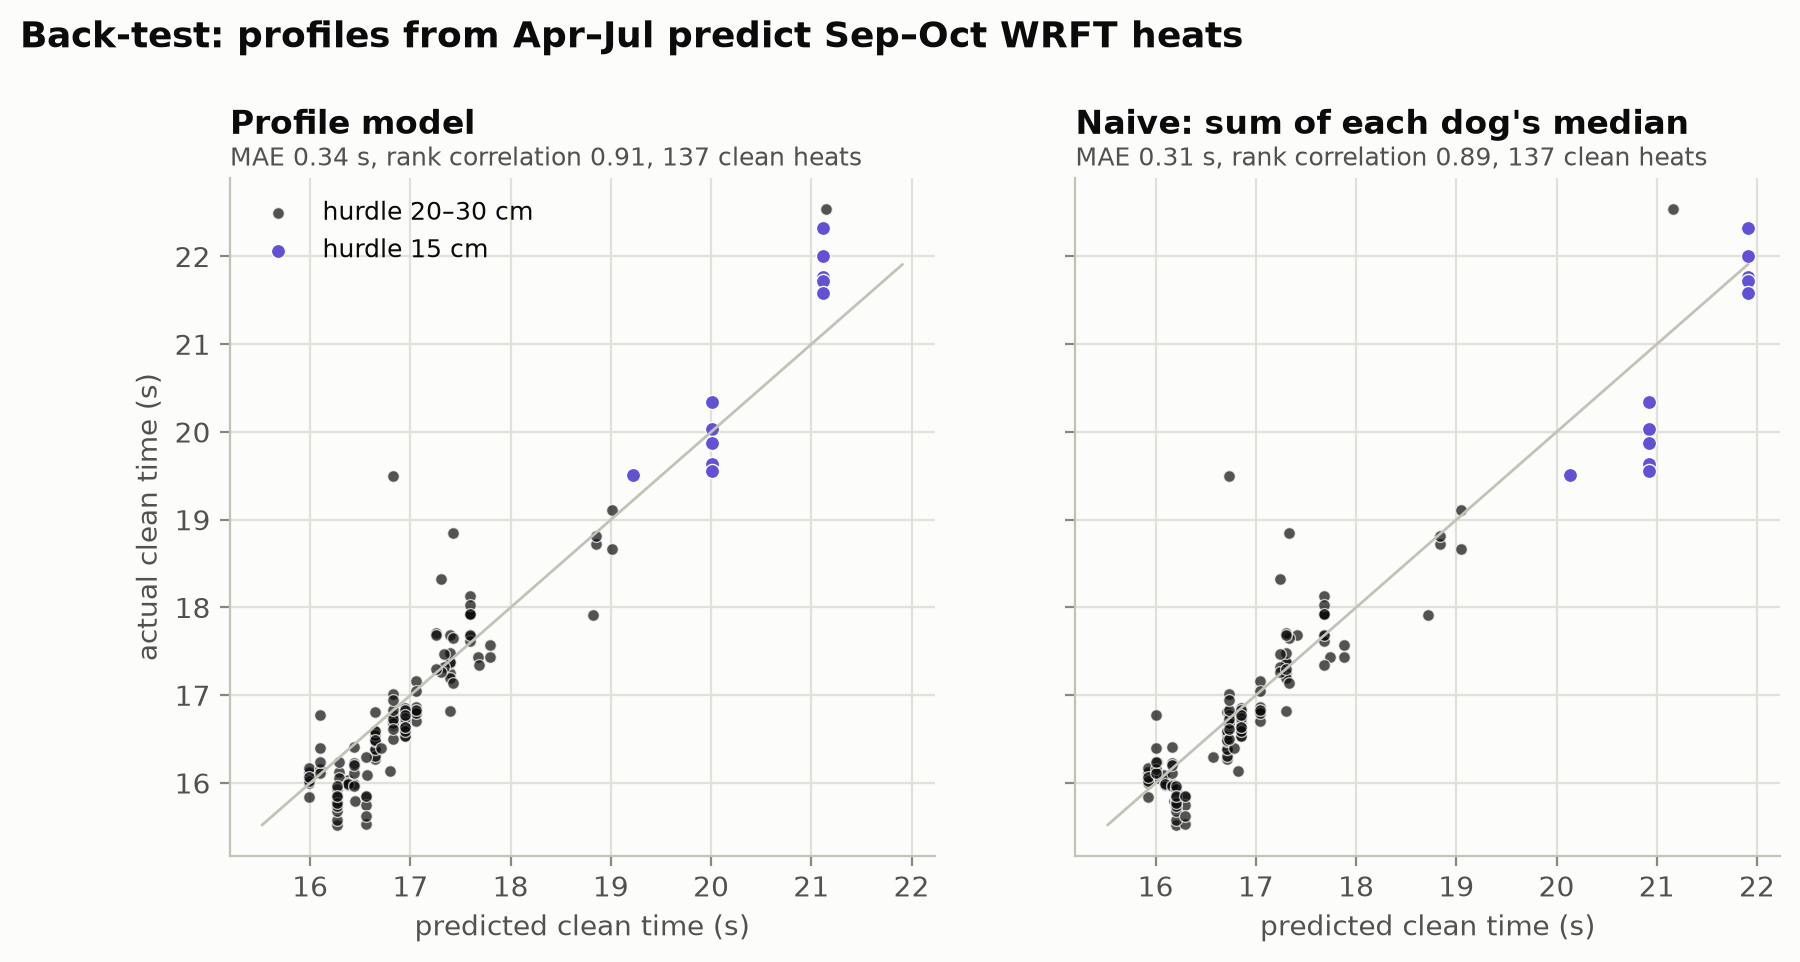

In [14]:
bt = lineup.backtest(t["runs"], t["heats"], t["dogs"], t["hurdle_check"])
display(bt["summary"])
print(bt["summary"].attrs)
display(bt["by_hurdle"], bt["calibration"])
display(Image(style.save(plots.lineup_backtest(bt["heats"]), "lineup_backtest", "phase4")))

- **Clean time:** the model ranks heats well (Spearman **0.91**; the naive sum of each dog's median gets 0.89). Its average error (0.34 s) is no better than the naive one (0.31 s) for the line-ups WRFT actually ran, because the naive sum already knows each dog's usual height.
- **Where the model earns its keep:** line-ups at an *unusual* height. At 15 cm the naive sum is 0.54 s too slow and the model 0.32 s too fast; overall MAE is 0.50 vs 0.64 s. The search needs exactly this, since it changes the hurdle.
- **Faults are hard to predict per dog** (AUC 0.55; the Brier score is only slightly better than a constant). P(clean) is too pessimistic in autumn (predicted 56 %, observed 64 %): the team got cleaner over the season. Read the fault part of the ranking as a tilt, not a forecast.
- 47 test heats had a dog with no Apr–Jul history (Easy, Milo, Kent) and were left out.

### 6. How stable is the A-team?

In [15]:
stab = lineup.stability(t["runs"], t["dogs"], t["hurdle_check"], cost, reps=50)
display(stab["summary"], stab["dogs"].head(10))

,reps,a_team,a_team_in_top_5
0,50,Alfie | Enola | Maggie | Pax,0.38


,dog,share_of_resamples
0,Enola,1.00
1,Alfie,0.72
2,Pax,0.58
3,Maggie,0.56
4,Alex,0.34
5,Tyna,0.32
6,Bree,0.12
7,Moon,0.12
8,Dixie,0.06
9,Ashley,0.04


- Over 50 resamples of competition days, **Enola is in the best line-up every time**, Alfie 72 %, Pax 58 %, Maggie 56 %. Alex and Tyna are the next choices (about a third each).
- The exact A-team stays in the top 5 in only 38 % of resamples: the top line-ups are within 0.2 s of each other. So the robust advice is **the core (Enola, Alfie, Maggie) plus two of Pax / Alex / Tyna, in the right order**, not one fixed four.

## Summary for Phase 5

| Topic | Finding | Confidence |
|---|---|---|
| Heat | +0.08 s per dog run per 10 °C above 20 °C (~0.3 s per heat on a 30 °C day) | high: all dogs, robust to every variant |
| Humidity, wind, rain | too small to matter for speed | high for speed; faults inconclusive |
| **Second day of an event** | **+16–19 pp clean heats** vs the first day, same teams | high; cause unknown |
| A-team | Maggie > Enola > Pax > Alfie, 16.6 s without faults / 19.3 s expected; Enola first is the proven alternative | core stable, 4th dog interchangeable |
| Order | Hopefuls −2.2 s by starting Maggie; XXL, Zephyr −1.0 to −1.3 s | model-based; starts are the driver |
| Height dog | none of WRFT's small dogs pays off in a top team | model-based |